<a href="https://colab.research.google.com/github/Tumisang-Precious/AI_for_Science_and_Engineering/blob/main/week6_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Programmatically generate synthetic soil swelling data since the file is missing
np.random.seed(42)
n_samples = 150

data = {
    'clay_content_pct': np.random.uniform(15, 65, n_samples),
    'liquid_limit_pct': np.random.uniform(30, 90, n_samples),
    'plasticity_index': np.random.uniform(10, 50, n_samples),
    'moisture_content_pct': np.random.uniform(10, 35, n_samples),
    'dry_density_g_cm3': np.random.uniform(1.3, 1.9, n_samples),
    'swelling_pressure_kPa': np.random.uniform(20, 350, n_samples)
}

synthetic_df = pd.DataFrame(data)
synthetic_df.to_csv('/content/soil_swelling_data.csv', index=False)
print("Synthetic soil swelling dataset generated and saved to '/content/soil_swelling_data.csv'")

# Load the dataset
df = pd.read_csv('/content/soil_swelling_data.csv')

# Inspect the dataset
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())

Synthetic soil swelling dataset generated and saved to '/content/soil_swelling_data.csv'
Dataset shape: (150, 6)
Column names: ['clay_content_pct', 'liquid_limit_pct', 'plasticity_index', 'moisture_content_pct', 'dry_density_g_cm3', 'swelling_pressure_kPa']


,clay_content_pct,liquid_limit_pct,plasticity_index,moisture_content_pct,dry_density_g_cm3,swelling_pressure_kPa
0,33.727006,84.495953,12.067269,29.428673,1.401361,58.576353
1,62.535715,44.373713,31.254185,23.960106,1.467154,330.144601
2,51.599697,38.693692,31.625405,20.605550,1.406206,227.143658
3,44.932924,59.367166,35.497196,32.658860,1.353222,130.518853
4,22.800932,89.139027,39.043653,12.779937,1.372382,65.959784


In [5]:
import os
# List all files in the current working directory to check if the file is there or named differently
print("Files in current directory:", os.listdir('.'))
if os.path.exists('/content'):
    print("Files in /content:", os.listdir('/content'))

Files in current directory: ['.config', 'soil_swelling_data.csv', 'sample_data']
Files in /content: ['.config', 'soil_swelling_data.csv', 'sample_data']


In [6]:
# Select numerical features
numeric_df = df.select_dtypes(include=np.number)

# Remove identifier columns if present
numeric_df = numeric_df.drop(
    columns=['ID', 'Sample_ID', 'Unnamed: 0'],
    errors='ignore'
)

# Remove rows with missing numerical values
X = numeric_df.dropna().copy()

print("Features used:", X.columns.tolist())
print("Samples used:", len(X))

# Standardise the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardised data shape:", X_scaled.shape)

Features used: ['clay_content_pct', 'liquid_limit_pct', 'plasticity_index', 'moisture_content_pct', 'dry_density_g_cm3', 'swelling_pressure_kPa']
Samples used: 150
Standardised data shape: (150, 6)


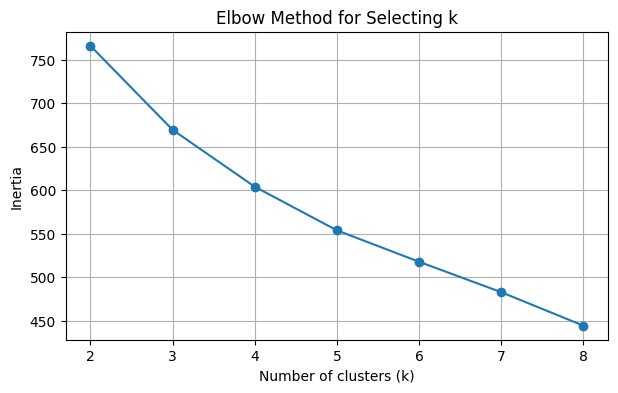

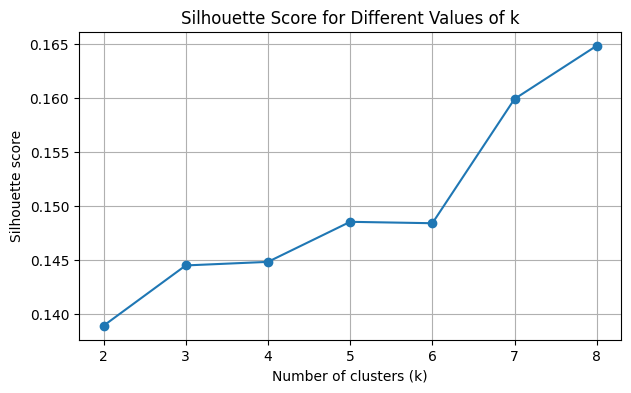

k=2: Inertia=766.29, Silhouette score=0.139
k=3: Inertia=669.65, Silhouette score=0.144
k=4: Inertia=604.11, Silhouette score=0.145
k=5: Inertia=553.93, Silhouette score=0.149
k=6: Inertia=517.76, Silhouette score=0.148
k=7: Inertia=482.75, Silhouette score=0.160
k=8: Inertia=444.21, Silhouette score=0.165


In [7]:
inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Plot the elbow curve
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Selecting k')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Plot silhouette scores
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), silhouette_scores, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette Score for Different Values of k')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Print the results
for k, inertia, score in zip(
    k_values, inertias, silhouette_scores
):
    print(f"k={k}: Inertia={inertia:.2f}, "
          f"Silhouette score={score:.3f}")

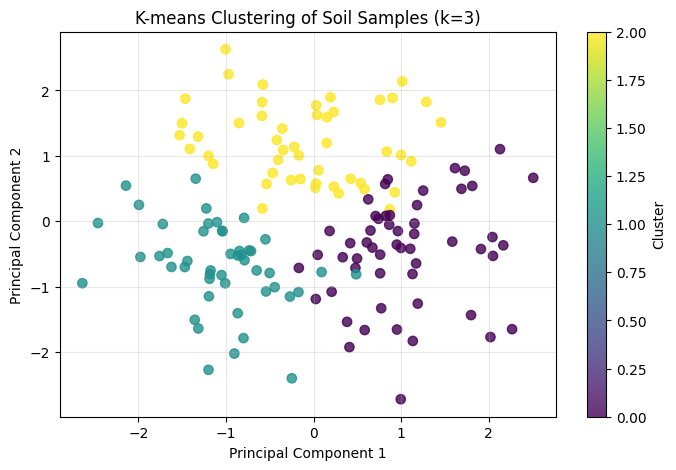

Variance explained by the two components: 39.89 %


In [8]:
# Replace 3 with the k selected from your results
best_k = 3

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

# Store cluster labels
clustered_data = X.copy()
clustered_data['Cluster'] = clusters

# Reduce the features to two dimensions for visualisation
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap='viridis',
    s=45,
    alpha=0.8
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title(f'K-means Clustering of Soil Samples (k={best_k})')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

print(
    "Variance explained by the two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

clay_content_pct                 liquid_limit_pct                  \
                    mean  median     std             mean  median     std   
Cluster                                                                     
0                 38.049  37.406  13.078           51.317  49.131  13.773   
1                 25.879  24.249   8.370           62.753  63.360  17.795   
2                 52.079  54.361   9.099           70.301  74.070  15.472   

        plasticity_index                 moisture_content_pct                 \
                    mean  median     std                 mean  median    std   
Cluster                                                                        
0                 36.278  38.227  10.009               26.083  26.741  6.903   
1                 30.210  31.311  12.001               20.334  19.447  7.516   
2                 22.246  22.265   9.845               22.628  24.678  7.402   

        dry_density_g_cm3               swelling_pressure_kPa                   
                     mean median    std                  mean   median     std  
Cluster                                                                         
0                   1.568  1.553  0.158               254.653  269.549  71.314  
1                   1.611  1.617  0.177                94.083   74.869  62.637  
2                   1.553  1.531  0.159               177.936  174.122  76.363


Samples per cluster:


,count
Cluster,
0,54
1,48
2,48


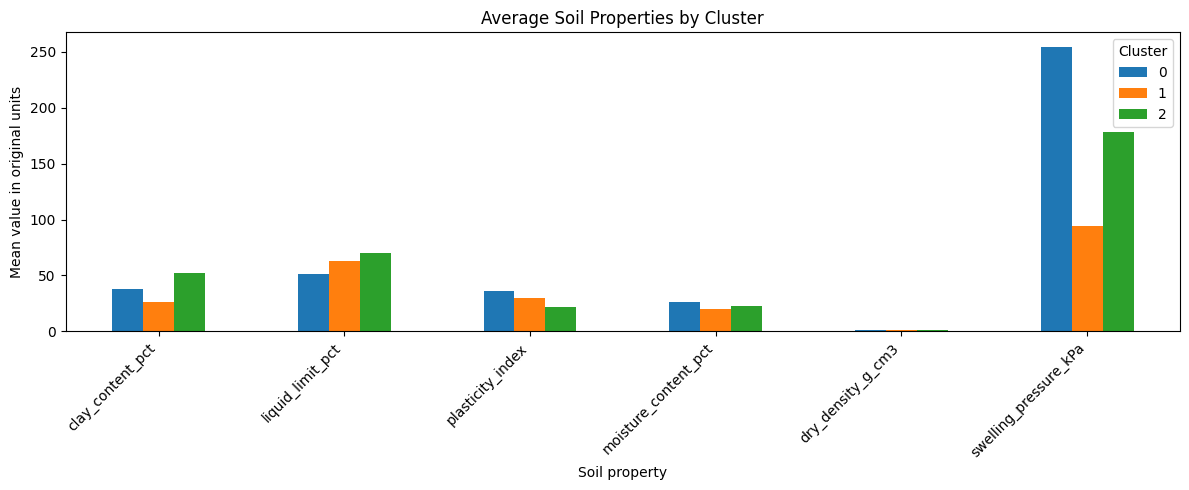

In [9]:
# Calculate average feature values for each cluster
cluster_summary = clustered_data.groupby('Cluster').agg(
    ['mean', 'median', 'std']
)

display(cluster_summary.round(3))

# Show the number of samples in each cluster
print("\nSamples per cluster:")
display(clustered_data['Cluster'].value_counts().sort_index())

# Compare mean feature values visually
cluster_means = clustered_data.groupby('Cluster').mean()

cluster_means.T.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.xlabel('Soil property')
plt.ylabel('Mean value in original units')
plt.title('Average Soil Properties by Cluster')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

## Discussion and Interpretation of Soil Clusters

K-means clustering was applied to the selected numerical soil properties to identify groups of samples with similar geotechnical characteristics. The features were standardised before clustering to prevent variables with larger numerical scales from dominating the distance calculations.

The number of clusters was investigated using the elbow method and silhouette score. The selected number of clusters was based on the observed clustering metrics and the interpretability of the resulting groups. Principal component analysis was used to visualise the clusters in two dimensions.

The characteristics of each cluster were examined using summary statistics for the original soil properties. Differences in swelling potential, plasticity and other available soil characteristics may reveal groups with different expansive-soil behaviour.

These groups could support preliminary identification of soils that warrant closer investigation when assessing foundations and moisture-related ground movement. However, the clusters do not directly predict building cracks or foundation failure. Such predictions would require relevant foundation performance, ground movement or building damage data and further validation.